<a href="https://colab.research.google.com/github/kassahun-12/DS-A5-Time-Series-Rolling-Evaluation/blob/main/Welcome_To_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**Name: Kassahun Azezew Ayidagn**
#**ID: 2026A8002209001**
#**DS-A5 | Time-Series Rolling Evaluation Lab**
**GitHub Link: https://github.com/kassahun-12/DS-A5-Time-Series-Rolling-Evaluation**

#**AI Use and Verification**
Generative AI assistance was used to support code debugging, explain evaluation metrics, interpret experimental outputs, and improve the organization and clarity of the report. The dataset processing, feature extraction, model execution, validation, and reported experimental results were checked against the executed Colab notebook and saved output files. AI-generated interpretations were reviewed and revised by the student. The reported numerical results are based on the experiments performed, not generated or simulated values.


In [3]:

# ============================================================
# DS-A5: FVC2004 DB1 + DB2
# Complete data preparation and temporal validation notebook
# ============================================================

!pip -q install numpy pandas matplotlib pillow scipy scikit-learn

import os
import re
import json
import glob
import hashlib
import platform
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image
from scipy.ndimage import sobel, gaussian_filter

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED)

print("Python:", platform.python_version())
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Random seed:", SEED)


Python: 3.13.18
NumPy: 2.4.6
Pandas: 2.2.3
Random seed: 42


#**Load FVC2004**

In [8]:


# ============================================================
# FIX: LOAD DB1_B AND DB2_B SEPARATELY
# ============================================================

from google.colab import files
import os
import zipfile
import glob
import pandas as pd
from pathlib import Path

BASE_DIR = "/content/FVC2004"

DB1_DIR = os.path.join(BASE_DIR, "DB1_B")
DB2_DIR = os.path.join(BASE_DIR, "DB2_B")

os.makedirs(DB1_DIR, exist_ok=True)
os.makedirs(DB2_DIR, exist_ok=True)

print("Upload DB1_B.zip and DB2_B.zip")

uploaded = files.upload()

for zip_name in uploaded:

    name = zip_name.lower()

    if not name.endswith(".zip"):
        continue

    if "db1" in name:
        destination = DB1_DIR

    elif "db2" in name:
        destination = DB2_DIR

    else:
        print("Unrecognized archive:", zip_name)
        continue

    print("Extracting:", zip_name)

    with zipfile.ZipFile(zip_name, "r") as z:
        z.extractall(destination)

    print("Extracted into:", destination)


# Find fingerprint images
IMAGE_EXTENSIONS = [
    "*.tif", "*.tiff", "*.bmp",
    "*.png", "*.jpg", "*.jpeg"
]

def find_images(folder):

    result = []

    for ext in IMAGE_EXTENSIONS:

        result.extend(
            glob.glob(
                os.path.join(folder, "**", ext),
                recursive=True
            )
        )

    return sorted(set(result))


db1_images = find_images(DB1_DIR)
db2_images = find_images(DB2_DIR)

print("\n========== DATASET SUMMARY ==========")

print("DB1_B images:", len(db1_images))
print("DB2_B images:", len(db2_images))

print("Total images:", len(db1_images) + len(db2_images))

if not db1_images or not db2_images:

    raise ValueError(
        "One database is empty. Check the uploaded ZIP filenames."
    )


# Create combined image list with verified source labels
image_records = []

for path in db1_images:

    image_records.append({
        "database": "DB1_B",
        "image_path": path,
        "filename": Path(path).name
    })

for path in db2_images:

    image_records.append({
        "database": "DB2_B",
        "image_path": path,
        "filename": Path(path).name
    })

image_df = pd.DataFrame(image_records)

display(image_df.head(10))

print("\nDatabase distribution:")
print(image_df["database"].value_counts())


Upload DB1_B.zip and DB2_B.zip


Saving DB2_B.zip to DB2_B (1).zip
Saving DB1_B.zip to DB1_B (1).zip
Extracting: DB2_B (1).zip
Extracted into: /content/FVC2004/DB2_B
Extracting: DB1_B (1).zip
Extracted into: /content/FVC2004/DB1_B

========== DATASET SUMMARY ==========
DB1_B images: 80
DB2_B images: 80
Total images: 160


,database,image_path,filename
0,DB1_B,/content/FVC2004/DB1_B/101_1.tif,101_1.tif
1,DB1_B,/content/FVC2004/DB1_B/101_2.tif,101_2.tif
2,DB1_B,/content/FVC2004/DB1_B/101_3.tif,101_3.tif
3,DB1_B,/content/FVC2004/DB1_B/101_4.tif,101_4.tif
4,DB1_B,/content/FVC2004/DB1_B/101_5.tif,101_5.tif
5,DB1_B,/content/FVC2004/DB1_B/101_6.tif,101_6.tif
6,DB1_B,/content/FVC2004/DB1_B/101_7.tif,101_7.tif
7,DB1_B,/content/FVC2004/DB1_B/101_8.tif,101_8.tif
8,DB1_B,/content/FVC2004/DB1_B/102_1.tif,102_1.tif
9,DB1_B,/content/FVC2004/DB1_B/102_2.tif,102_2.tif



Database distribution:
database
DB1_B    80
DB2_B    80
Name: count, dtype: int64


**Extract features and preserve impression identifiers**

In [9]:

# ============================================================
# DS-A5: FEATURE EXTRACTION
# DB1_B + DB2_B
# ============================================================

import numpy as np
import pandas as pd
from PIL import Image
from scipy.ndimage import sobel, gaussian_filter
from pathlib import Path

def extract_fingerprint_features(path):

    image = Image.open(path).convert("L")

    arr = np.asarray(image, dtype=np.float32) / 255.0

    gx = sobel(arr, axis=1)
    gy = sobel(arr, axis=0)

    gradient = np.sqrt(gx**2 + gy**2)

    angle = np.arctan2(gy, gx)

    orientation = np.abs(
        np.mean(np.exp(2j * angle))
    )

    return {
        "mean_intensity": float(arr.mean()),
        "contrast": float(arr.std()),

        "sharpness": float(
            np.var(
                gaussian_filter(arr, 1)
                - gaussian_filter(arr, 2)
            )
        ),

        "gradient_mean": float(gradient.mean()),
        "gradient_std": float(gradient.std()),

        "orientation_consistency": float(orientation)
    }


results = []

for _, row in image_df.iterrows():

    filename = Path(row["filename"]).stem

    # Parse the filename: 101_1 -> finger 101, impression 1
    match = __import__("re").fullmatch(
        r"(\d+)_(\d+)", filename
    )

    if match is None:
        print("Unrecognized filename:", filename)
        continue

    finger_id = int(match.group(1))
    impression_id = int(match.group(2))

    features = extract_fingerprint_features(
        row["image_path"]
    )

    results.append({
        "database": row["database"],
        "finger_id": finger_id,
        "impression_id": impression_id,
        "filename": row["filename"],
        **features
    })


feature_df = pd.DataFrame(results)

print("Feature extraction completed:", feature_df.shape)

display(feature_df.head(10))

print("\nImages per database:")
display(feature_df.groupby("database").size())

print("\nImages per finger:")
display(
    feature_df.groupby(
        ["database", "finger_id"]
    ).size().unstack()
)

feature_df.to_csv(
    "/content/FVC2004_DB1_DB2_features.csv",
    index=False
)


Feature extraction completed: (160, 10)


,database,finger_id,impression_id,filename,mean_intensity,contrast,sharpness,gradient_mean,gradient_std,orientation_consistency
0,DB1_B,101,1,101_1.tif,0.973640,0.103835,0.000773,0.115561,0.373633,0.827652
1,DB1_B,101,2,101_2.tif,0.874514,0.240950,0.001295,0.221315,0.458313,0.630989
2,DB1_B,101,3,101_3.tif,0.942947,0.163118,0.001393,0.177180,0.468001,0.724984
3,DB1_B,101,4,101_4.tif,0.947522,0.157226,0.001433,0.186950,0.488491,0.754722
4,DB1_B,101,5,101_5.tif,0.965836,0.110260,0.000988,0.161581,0.418765,0.755738
5,DB1_B,101,6,101_6.tif,0.941736,0.168199,0.001746,0.216672,0.529934,0.733775
6,DB1_B,101,7,101_7.tif,0.947575,0.162975,0.001907,0.215836,0.559904,0.749077
7,DB1_B,101,8,101_8.tif,0.849160,0.308834,0.000945,0.146339,0.442714,0.740060
8,DB1_B,102,1,102_1.tif,0.965022,0.140277,0.001279,0.135857,0.472058,0.887708
9,DB1_B,102,2,102_2.tif,0.833579,0.294639,0.001780,0.267648,0.544896,0.667560



Images per database:


,0
database,
DB1_B,80
DB2_B,80



Images per finger:


finger_id,101,102,103,104,105,106,107,108,109,110
database,,,,,,,,,,
DB1_B,8,8,8,8,8,8,8,8,8,8
DB2_B,8,8,8,8,8,8,8,8,8,8


**Verify the dataset structure**

In [10]:

# Check missing values
print("Missing values:")
display(feature_df.isna().sum())

# Check duplicate records
print(
    "Duplicate records:",
    feature_df.duplicated(
        ["database", "finger_id", "impression_id"]
    ).sum()
)

# Check impressions per finger
print("\nImpression counts:")

display(
    feature_df.groupby(
        ["database", "finger_id"]
    )["impression_id"].agg(
        ["count", "min", "max", "nunique"]
    )
)

# Check whether each finger has impressions 1 through 8
for db in ["DB1_B", "DB2_B"]:

    for finger in range(101, 111):

        observed = sorted(
            feature_df.loc[
                (feature_df.database == db) &
                (feature_df.finger_id == finger),
                "impression_id"
            ].tolist()
        )

        if observed != list(range(1, 9)):

            print(
                "Check:",
                db,
                finger,
                observed
            )


Missing values:


,0
database,0
finger_id,0
impression_id,0
filename,0
mean_intensity,0
contrast,0
sharpness,0
gradient_mean,0
gradient_std,0
orientation_consistency,0


Duplicate records: 0

Impression counts:


count  min  max  nunique
database finger_id                          
DB1_B    101            8    1    8        8
         102            8    1    8        8
         103            8    1    8        8
         104            8    1    8        8
         105            8    1    8        8
         106            8    1    8        8
         107            8    1    8        8
         108            8    1    8        8
         109            8    1    8        8
         110            8    1    8        8
DB2_B    101            8    1    8        8
         102            8    1    8        8
         103            8    1    8        8
         104            8    1    8        8
         105            8    1    8        8
         106            8    1    8        8
         107            8    1    8        8
         108            8    1    8        8
         109            8    1    8        8
         110            8    1    8        8

**Next validation experiment**

In [11]:

# Inspect image dimensions and impression sequence

for db in ["DB1_B", "DB2_B"]:

    print("\nDATABASE:", db)

    for finger in [101, 102, 103]:

        subset = feature_df[
            (feature_df["database"] == db) &
            (feature_df["finger_id"] == finger)
        ].sort_values("impression_id")

        print(f"\nFinger {finger}")

        display(
            subset[
                [
                    "filename",
                    "impression_id",
                    "contrast",
                    "sharpness",
                    "gradient_mean"
                ]
            ]
        )



DATABASE: DB1_B

Finger 101


,filename,impression_id,contrast,sharpness,gradient_mean
0,101_1.tif,1,0.103835,0.000773,0.115561
1,101_2.tif,2,0.240950,0.001295,0.221315
2,101_3.tif,3,0.163118,0.001393,0.177180
3,101_4.tif,4,0.157226,0.001433,0.186950
4,101_5.tif,5,0.110260,0.000988,0.161581
5,101_6.tif,6,0.168199,0.001746,0.216672
6,101_7.tif,7,0.162975,0.001907,0.215836
7,101_8.tif,8,0.308834,0.000945,0.146339



Finger 102


,filename,impression_id,contrast,sharpness,gradient_mean
8,102_1.tif,1,0.140277,0.001279,0.135857
9,102_2.tif,2,0.294639,0.001780,0.267648
10,102_3.tif,3,0.269230,0.002847,0.311276
11,102_4.tif,4,0.276074,0.001696,0.250498
12,102_5.tif,5,0.244261,0.002190,0.294082
13,102_6.tif,6,0.177742,0.002171,0.237011
14,102_7.tif,7,0.198793,0.002400,0.255489
15,102_8.tif,8,0.309649,0.001687,0.220607



Finger 103


,filename,impression_id,contrast,sharpness,gradient_mean
16,103_1.tif,1,0.187781,0.002199,0.231230
17,103_2.tif,2,0.096997,0.000769,0.102290
18,103_3.tif,3,0.295968,0.001617,0.272954
19,103_4.tif,4,0.264810,0.002505,0.278137
20,103_5.tif,5,0.261980,0.002004,0.260856
21,103_6.tif,6,0.120864,0.001144,0.170647
22,103_7.tif,7,0.246503,0.002037,0.248721
23,103_8.tif,8,0.305737,0.001920,0.240016


... (2 outputs left out)


Finger 102


,filename,impression_id,contrast,sharpness,gradient_mean
88,102_1.tif,1,0.211865,0.001580,0.387835
89,102_2.tif,2,0.194673,0.001494,0.371774
90,102_3.tif,3,0.237256,0.002232,0.481159
91,102_4.tif,4,0.199802,0.001272,0.331019
92,102_5.tif,5,0.116322,0.000412,0.179519
93,102_6.tif,6,0.198678,0.001149,0.308484
94,102_7.tif,7,0.148102,0.001035,0.312166
95,102_8.tif,8,0.312867,0.002448,0.489789



Finger 103


,filename,impression_id,contrast,sharpness,gradient_mean
96,103_1.tif,1,0.207085,0.001534,0.391003
97,103_2.tif,2,0.129154,0.000561,0.216730
98,103_3.tif,3,0.282889,0.002058,0.474867
99,103_4.tif,4,0.146084,0.000602,0.219332
100,103_5.tif,5,0.153647,0.000983,0.319429
101,103_6.tif,6,0.171397,0.001027,0.312078
102,103_7.tif,7,0.204068,0.001788,0.439793
103,103_8.tif,8,0.245875,0.001332,0.363080


In [12]:
for db in ["DB1_B", "DB2_B"]:
    print("\nDATABASE:", db)

    for finger in [101, 102, 103]:
        subset = feature_df[
            (feature_df["database"] == db) &
            (feature_df["finger_id"] == finger)
        ].sort_values("impression_id")

        print(f"\nFinger {finger}")
        display(
            subset[
                [
                    "filename",
                    "impression_id",
                    "contrast",
                    "sharpness",
                    "gradient_mean",
                    "gradient_std"
                ]
            ]
        )


DATABASE: DB1_B

Finger 101


,filename,impression_id,contrast,sharpness,gradient_mean,gradient_std
0,101_1.tif,1,0.103835,0.000773,0.115561,0.373633
1,101_2.tif,2,0.240950,0.001295,0.221315,0.458313
2,101_3.tif,3,0.163118,0.001393,0.177180,0.468001
3,101_4.tif,4,0.157226,0.001433,0.186950,0.488491
4,101_5.tif,5,0.110260,0.000988,0.161581,0.418765
5,101_6.tif,6,0.168199,0.001746,0.216672,0.529934
6,101_7.tif,7,0.162975,0.001907,0.215836,0.559904
7,101_8.tif,8,0.308834,0.000945,0.146339,0.442714



Finger 102


,filename,impression_id,contrast,sharpness,gradient_mean,gradient_std
8,102_1.tif,1,0.140277,0.001279,0.135857,0.472058
9,102_2.tif,2,0.294639,0.001780,0.267648,0.544896
10,102_3.tif,3,0.269230,0.002847,0.311276,0.678913
11,102_4.tif,4,0.276074,0.001696,0.250498,0.526981
12,102_5.tif,5,0.244261,0.002190,0.294082,0.585507
13,102_6.tif,6,0.177742,0.002171,0.237011,0.597426
14,102_7.tif,7,0.198793,0.002400,0.255489,0.620737
15,102_8.tif,8,0.309649,0.001687,0.220607,0.550667



Finger 103


,filename,impression_id,contrast,sharpness,gradient_mean,gradient_std
16,103_1.tif,1,0.187781,0.002199,0.231230,0.595373
17,103_2.tif,2,0.096997,0.000769,0.102290,0.380775
18,103_3.tif,3,0.295968,0.001617,0.272954,0.504782
19,103_4.tif,4,0.264810,0.002505,0.278137,0.639474
20,103_5.tif,5,0.261980,0.002004,0.260856,0.573570
21,103_6.tif,6,0.120864,0.001144,0.170647,0.453278
22,103_7.tif,7,0.246503,0.002037,0.248721,0.588212
23,103_8.tif,8,0.305737,0.001920,0.240016,0.581048


... (2 outputs left out)


Finger 102


,filename,impression_id,contrast,sharpness,gradient_mean,gradient_std
88,102_1.tif,1,0.211865,0.001580,0.387835,0.409350
89,102_2.tif,2,0.194673,0.001494,0.371774,0.398051
90,102_3.tif,3,0.237256,0.002232,0.481159,0.453675
91,102_4.tif,4,0.199802,0.001272,0.331019,0.381095
92,102_5.tif,5,0.116322,0.000412,0.179519,0.240630
93,102_6.tif,6,0.198678,0.001149,0.308484,0.369232
94,102_7.tif,7,0.148102,0.001035,0.312166,0.342053
95,102_8.tif,8,0.312867,0.002448,0.489789,0.520446



Finger 103


,filename,impression_id,contrast,sharpness,gradient_mean,gradient_std
96,103_1.tif,1,0.207085,0.001534,0.391003,0.407413
97,103_2.tif,2,0.129154,0.000561,0.216730,0.274907
98,103_3.tif,3,0.282889,0.002058,0.474867,0.461808
99,103_4.tif,4,0.146084,0.000602,0.219332,0.288836
100,103_5.tif,5,0.153647,0.000983,0.319429,0.318438
101,103_6.tif,6,0.171397,0.001027,0.312078,0.344351
102,103_7.tif,7,0.204068,0.001788,0.439793,0.416440
103,103_8.tif,8,0.245875,0.001332,0.363080,0.390042


In [13]:
import zipfile
import os

zip_files = [
    "/content/DB1_B.zip",
    "/content/DB2_B.zip"
]

for zip_path in zip_files:
    print("\nZIP FILE:", os.path.basename(zip_path))

    if not os.path.exists(zip_path):
        print("File not found:", zip_path)
        continue

    with zipfile.ZipFile(zip_path, "r") as z:
        for name in z.namelist():
            lower = name.lower()

            if any(ext in lower for ext in [
                ".txt", ".readme", ".csv", ".xml",
                ".json", ".pdf", ".xls"
            ]):
                print(name)


ZIP FILE: DB1_B.zip

ZIP FILE: DB2_B.zip


In [14]:
from PIL import Image
import os

image_paths = [
    "/content/FVC2004/DB1_B/101_1.tif",
    "/content/FVC2004/DB1_B/101_2.tif",
    "/content/FVC2004/DB2_B/101_1.tif"
]

for path in image_paths:
    print("\nIMAGE:", path)

    with Image.open(path) as img:
        print("Dimensions:", img.size)
        print("TIFF metadata:", img.tag_v2)


IMAGE: /content/FVC2004/DB1_B/101_1.tif
Dimensions: (640, 480)
TIFF metadata: {256: 640, 257: 480, 258: (8,), 259: 1, 262: 1, 273: (512,), 277: 1, 278: 480, 279: (307200,), 284: 1, 254: 0}

IMAGE: /content/FVC2004/DB1_B/101_2.tif
Dimensions: (640, 480)
TIFF metadata: {256: 640, 257: 480, 258: (8,), 259: 1, 262: 1, 273: (512,), 277: 1, 278: 480, 279: (307200,), 284: 1, 254: 0}

IMAGE: /content/FVC2004/DB2_B/101_1.tif
Dimensions: (328, 364)
TIFF metadata: {256: 328, 257: 364, 258: (8,), 259: 1, 262: 1, 273: (512,), 277: 1, 278: 364, 279: (119392,), 284: 1, 254: 0}


In [15]:

# DS-A5: Prepare the initial modeling table
import pandas as pd

model_df = feature_df.copy()

# Initial prediction target
target = "sharpness"

# Candidate input features
features = [
    "mean_intensity",
    "contrast",
    "gradient_mean",
    "gradient_std",
    "orientation_consistency"
]

# Check dataset completeness
print("Modeling dataset:", model_df.shape)
print("\nMissing values:")
print(model_df[features + [target]].isna().sum())

print("\nNumber of fingers:")
print(model_df.groupby("database")["finger_id"].nunique())

print("\nImages per finger:")
print(
    model_df.groupby(["database", "finger_id"])
    .size()
    .value_counts()
)

print("\nTarget summary:")
display(model_df[target].describe())

print("\nModeling table:")
display(
    model_df[
        ["database", "finger_id", "impression_id"]
        + features + [target]
    ].head(10)
)


Modeling dataset: (160, 10)

Missing values:
mean_intensity             0
contrast                   0
gradient_mean              0
gradient_std               0
orientation_consistency    0
sharpness                  0
dtype: int64

Number of fingers:
database
DB1_B    10
DB2_B    10
Name: finger_id, dtype: int64

Images per finger:
8    20
Name: count, dtype: int64

Target summary:


,sharpness
count,160.000000
mean,0.001501
std,0.000612
min,0.000264
25%,0.001053
50%,0.001488
75%,0.001920
max,0.002926



Modeling table:


,database,finger_id,impression_id,mean_intensity,contrast,gradient_mean,gradient_std,orientation_consistency,sharpness
0,DB1_B,101,1,0.973640,0.103835,0.115561,0.373633,0.827652,0.000773
1,DB1_B,101,2,0.874514,0.240950,0.221315,0.458313,0.630989,0.001295
2,DB1_B,101,3,0.942947,0.163118,0.177180,0.468001,0.724984,0.001393
3,DB1_B,101,4,0.947522,0.157226,0.186950,0.488491,0.754722,0.001433
4,DB1_B,101,5,0.965836,0.110260,0.161581,0.418765,0.755738,0.000988
5,DB1_B,101,6,0.941736,0.168199,0.216672,0.529934,0.733775,0.001746
6,DB1_B,101,7,0.947575,0.162975,0.215836,0.559904,0.749077,0.001907
7,DB1_B,101,8,0.849160,0.308834,0.146339,0.442714,0.740060,0.000945
8,DB1_B,102,1,0.965022,0.140277,0.135857,0.472058,0.887708,0.001279
9,DB1_B,102,2,0.833579,0.294639,0.267648,0.544896,0.667560,0.001780


#**Prepare the modeling dataset**

In [16]:

# DS-A5 | Step 1: Prepare modeling dataset

import pandas as pd
import numpy as np

model_df = feature_df.copy()

# Define the prediction target
target = "sharpness"

# Define input features
features = [
    "mean_intensity",
    "contrast",
    "gradient_mean",
    "gradient_std",
    "orientation_consistency"
]

# Create a unique identity group
# Same finger's impressions must remain in one validation fold.
model_df["group_id"] = (
    model_df["database"].astype(str)
    + "_"
    + model_df["finger_id"].astype(str)
)

# Keep only required columns
model_df = model_df[
    [
        "database",
        "finger_id",
        "impression_id",
        "filename",
        "group_id"
    ] + features + [target]
].copy()

# Basic validation
assert model_df.shape[0] == 160
assert model_df[features + [target]].notna().all().all()
assert model_df["group_id"].nunique() == 20

print("Modeling dataset shape:", model_df.shape)
print("Independent finger groups:", model_df["group_id"].nunique())

print("\nImages per database:")
display(model_df.groupby("database").size())

print("\nFinger groups per database:")
display(model_df.groupby("database")["group_id"].nunique())

print("\nImages per finger group:")
display(model_df.groupby("group_id").size().value_counts())

print("\nTarget statistics:")
display(model_df.groupby("database")[target].describe())

print("\nFirst 10 modeling records:")
display(model_df.head(10))


Modeling dataset shape: (160, 11)
Independent finger groups: 20

Images per database:


,0
database,
DB1_B,80
DB2_B,80



Finger groups per database:


,group_id
database,
DB1_B,10
DB2_B,10



Images per finger group:


,count
8,20



Target statistics:


,count,mean,std,min,25%,50%,75%,max
database,,,,,,,,
DB1_B,80.0,0.001685,0.000536,0.000580,0.001310,0.001688,0.002021,0.002917
DB2_B,80.0,0.001317,0.000630,0.000264,0.000936,0.001236,0.001793,0.002926



First 10 modeling records:


,database,finger_id,impression_id,filename,group_id,mean_intensity,contrast,gradient_mean,gradient_std,orientation_consistency,sharpness
0,DB1_B,101,1,101_1.tif,DB1_B_101,0.973640,0.103835,0.115561,0.373633,0.827652,0.000773
1,DB1_B,101,2,101_2.tif,DB1_B_101,0.874514,0.240950,0.221315,0.458313,0.630989,0.001295
2,DB1_B,101,3,101_3.tif,DB1_B_101,0.942947,0.163118,0.177180,0.468001,0.724984,0.001393
3,DB1_B,101,4,101_4.tif,DB1_B_101,0.947522,0.157226,0.186950,0.488491,0.754722,0.001433
4,DB1_B,101,5,101_5.tif,DB1_B_101,0.965836,0.110260,0.161581,0.418765,0.755738,0.000988
5,DB1_B,101,6,101_6.tif,DB1_B_101,0.941736,0.168199,0.216672,0.529934,0.733775,0.001746
6,DB1_B,101,7,101_7.tif,DB1_B_101,0.947575,0.162975,0.215836,0.559904,0.749077,0.001907
7,DB1_B,101,8,101_8.tif,DB1_B_101,0.849160,0.308834,0.146339,0.442714,0.740060,0.000945
8,DB1_B,102,1,102_1.tif,DB1_B_102,0.965022,0.140277,0.135857,0.472058,0.887708,0.001279
9,DB1_B,102,2,102_2.tif,DB1_B_102,0.833579,0.294639,0.267648,0.544896,0.667560,0.001780


**Examine the target and input features**

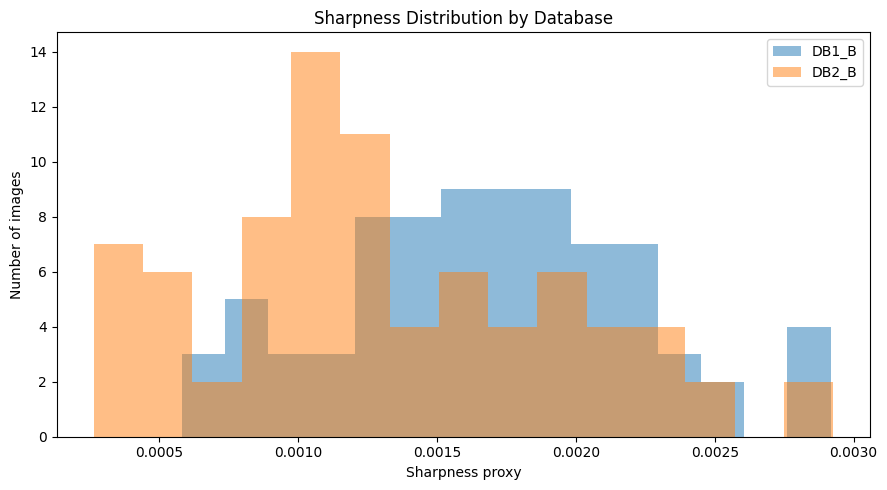

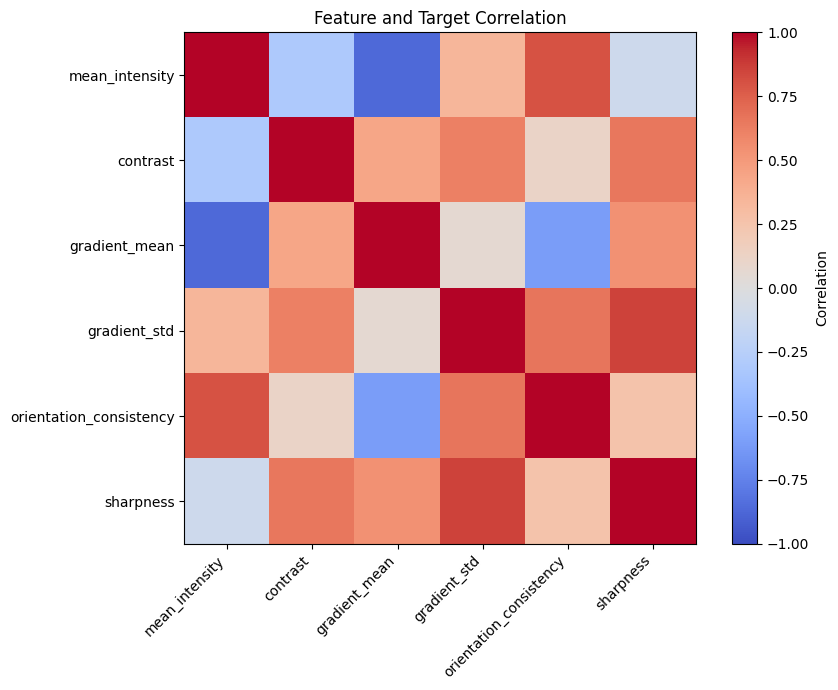

,sharpness
sharpness,1.000000
gradient_std,0.854985
contrast,0.655038
gradient_mean,0.532426
orientation_consistency,0.256787
mean_intensity,-0.114976


In [17]:

# DS-A5 | Step 2: Exploratory analysis

import matplotlib.pyplot as plt

# Target distribution
plt.figure(figsize=(9, 5))

for database in sorted(model_df["database"].unique()):
    values = model_df.loc[
        model_df["database"] == database, target
    ]
    plt.hist(values, bins=15, alpha=0.5, label=database)

plt.xlabel("Sharpness proxy")
plt.ylabel("Number of images")
plt.title("Sharpness Distribution by Database")
plt.legend()
plt.tight_layout()
plt.show()

# Feature correlation
correlation = model_df[features + [target]].corr()

plt.figure(figsize=(9, 7))
plt.imshow(correlation, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")

plt.xticks(
    range(len(correlation.columns)),
    correlation.columns,
    rotation=45,
    ha="right"
)
plt.yticks(range(len(correlation.index)), correlation.index)

plt.title("Feature and Target Correlation")
plt.tight_layout()
plt.show()

display(correlation[target].sort_values(ascending=False))


**Establish leakage-safe validation folds**

In [18]:

# DS-A5 | Step 3: Inspect grouped validation folds

from sklearn.model_selection import GroupKFold

X = model_df[features]
y = model_df[target]
groups = model_df["group_id"]

gkf = GroupKFold(n_splits=5)

fold_results = []

for fold, (train_idx, test_idx) in enumerate(
    gkf.split(X, y, groups=groups), start=1
):
    train_groups = set(groups.iloc[train_idx])
    test_groups = set(groups.iloc[test_idx])

    # Leakage assertions
    assert train_groups.isdisjoint(test_groups)

    fold_results.append({
        "fold": fold,
        "train_images": len(train_idx),
        "test_images": len(test_idx),
        "train_groups": len(train_groups),
        "test_groups": len(test_groups),
        "overlapping_groups": len(train_groups & test_groups)
    })

fold_df = pd.DataFrame(fold_results)

display(fold_df)

assert (fold_df["overlapping_groups"] == 0).all()

print("All five folds passed the group-leakage checks.")


,fold,train_images,test_images,train_groups,test_groups,overlapping_groups
0,1,128,32,16,4,0
1,2,128,32,16,4,0
2,3,128,32,16,4,0
3,4,128,32,16,4,0
4,5,128,32,16,4,0


All five folds passed the group-leakage checks.


#**Train the baseline and Random Forest**

In [19]:

# DS-A5 | Step 4: Baseline vs Random Forest

import numpy as np
import pandas as pd

from sklearn.model_selection import GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Rebuild X, y and groups from the modeling table
X = model_df[features].copy()
y = model_df[target].copy()
groups = model_df["group_id"].copy()

gkf = GroupKFold(n_splits=5)

results = []
predictions = []

for fold, (train_idx, test_idx) in enumerate(
    gkf.split(X, y, groups=groups), start=1
):

    X_train = X.iloc[train_idx]
    X_test = X.iloc[test_idx]

    y_train = y.iloc[train_idx]
    y_test = y.iloc[test_idx]

    train_groups = set(groups.iloc[train_idx])
    test_groups = set(groups.iloc[test_idx])

    # Leakage protection
    assert train_groups.isdisjoint(test_groups)

    # Baseline: training-fold mean
    baseline = DummyRegressor(strategy="mean")
    baseline.fit(X_train, y_train)
    baseline_pred = baseline.predict(X_test)

    # Random Forest with fold-specific imputation
    rf_model = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestRegressor(
            n_estimators=300,
            min_samples_leaf=2,
            random_state=42,
            n_jobs=-1
        ))
    ])

    rf_model.fit(X_train, y_train)
    rf_pred = rf_model.predict(X_test)

    # Evaluate both models
    for model_name, pred in [
        ("Baseline", baseline_pred),
        ("Random Forest", rf_pred)
    ]:
        results.append({
            "fold": fold,
            "model": model_name,
            "MAE": mean_absolute_error(y_test, pred),
            "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
            "R2": r2_score(y_test, pred)
        })

        for index, actual, predicted in zip(
            test_idx, y_test, pred
        ):
            predictions.append({
                "fold": fold,
                "model": model_name,
                "database": model_df.iloc[index]["database"],
                "finger_id": model_df.iloc[index]["finger_id"],
                "impression_id": model_df.iloc[index]["impression_id"],
                "actual_sharpness": actual,
                "predicted_sharpness": predicted
            })

results_df = pd.DataFrame(results)
predictions_df = pd.DataFrame(predictions)

print("FOLD-BY-FOLD PERFORMANCE")
display(results_df.round(6))

print("\nAVERAGE PERFORMANCE")
summary_df = (
    results_df.groupby("model")[["MAE", "RMSE", "R2"]]
    .agg(["mean", "std"])
)
display(summary_df.round(6))

print("\nPrediction records:", len(predictions_df))
print("Expected records:", 160 * 2)

assert len(predictions_df) == 160 * 2
assert not predictions_df.isna().any().any()

print("\nBoth models completed all five folds.")


FOLD-BY-FOLD PERFORMANCE


,fold,model,MAE,RMSE,R2
0,1,Baseline,0.000485,0.000621,-0.000053
1,1,Random Forest,0.000130,0.000165,0.929394
2,2,Baseline,0.000414,0.000482,-0.006449
3,2,Random Forest,0.000073,0.000090,0.964593
4,3,Baseline,0.000462,0.000544,-0.003249
5,3,Random Forest,0.000069,0.000090,0.972563
6,4,Baseline,0.000657,0.000766,-0.005626
7,4,Random Forest,0.000090,0.000117,0.976410
8,5,Baseline,0.000493,0.000599,-0.000165
9,5,Random Forest,0.000106,0.000148,0.938803



AVERAGE PERFORMANCE


MAE                RMSE                  R2          
                   mean       std      mean       std      mean       std
model                                                                    
Baseline       0.000502  0.000092  0.000603  0.000106 -0.003108  0.002980
Random Forest  0.000094  0.000025  0.000122  0.000034  0.956353  0.021022


Prediction records: 320
Expected records: 320

Both models completed all five folds.


#**Save the raw results**

In [20]:

# DS-A5 | Step 5: Save reproducible results

output_dir = "/content/DS_A5_results"
import os
os.makedirs(output_dir, exist_ok=True)

results_df.to_csv(
    f"{output_dir}/fold_metrics.csv",
    index=False
)

predictions_df.to_csv(
    f"{output_dir}/predictions.csv",
    index=False
)

model_df.to_csv(
    f"{output_dir}/modeling_dataset.csv",
    index=False
)

print("Saved files:")
print(os.listdir(output_dir))


Saved files:
['predictions.csv', 'modeling_dataset.csv', 'fold_metrics.csv']


**inspect model performance**

In [21]:

# DS-A5 | Step 6: Review saved experiment results

import pandas as pd

results_df = pd.read_csv(
    "/content/DS_A5_results/fold_metrics.csv"
)

predictions_df = pd.read_csv(
    "/content/DS_A5_results/predictions.csv"
)

print("FOLD-BY-FOLD RESULTS")
display(results_df.round(6))

print("\nAVERAGE PERFORMANCE")
summary = results_df.groupby("model").agg({
    "MAE": ["mean", "std"],
    "RMSE": ["mean", "std"],
    "R2": ["mean", "std"]
})

display(summary.round(6))

print("\nPREDICTION DATA")
display(predictions_df.head(10))

print("\nNumber of predictions:")
print(predictions_df.groupby("model").size())


FOLD-BY-FOLD RESULTS


,fold,model,MAE,RMSE,R2
0,1,Baseline,0.000485,0.000621,-0.000053
1,1,Random Forest,0.000130,0.000165,0.929394
2,2,Baseline,0.000414,0.000482,-0.006449
3,2,Random Forest,0.000073,0.000090,0.964593
4,3,Baseline,0.000462,0.000544,-0.003249
5,3,Random Forest,0.000069,0.000090,0.972563
6,4,Baseline,0.000657,0.000766,-0.005626
7,4,Random Forest,0.000090,0.000117,0.976410
8,5,Baseline,0.000493,0.000599,-0.000165
9,5,Random Forest,0.000106,0.000148,0.938803



AVERAGE PERFORMANCE


MAE                RMSE                  R2          
                   mean       std      mean       std      mean       std
model                                                                    
Baseline       0.000502  0.000092  0.000603  0.000106 -0.003108  0.002980
Random Forest  0.000094  0.000025  0.000122  0.000034  0.956353  0.021022


PREDICTION DATA


,fold,model,database,finger_id,impression_id,actual_sharpness,predicted_sharpness
0,1,Baseline,DB1_B,105,1,0.000698,0.001502
1,1,Baseline,DB1_B,105,2,0.002027,0.001502
2,1,Baseline,DB1_B,105,3,0.001558,0.001502
3,1,Baseline,DB1_B,105,4,0.002156,0.001502
4,1,Baseline,DB1_B,105,5,0.001654,0.001502
5,1,Baseline,DB1_B,105,6,0.001350,0.001502
6,1,Baseline,DB1_B,105,7,0.002917,0.001502
7,1,Baseline,DB1_B,105,8,0.002773,0.001502
8,1,Baseline,DB1_B,110,1,0.001244,0.001502
9,1,Baseline,DB1_B,110,2,0.001216,0.001502



Number of predictions:
model
Baseline         160
Random Forest    160
dtype: int64


#**Analyze errors by sensor**

In [22]:

# DS-A5 | Step 7: Error analysis by database

import numpy as np
import pandas as pd

pred = predictions_df.copy()

pred["error"] = (
    pred["predicted_sharpness"] - pred["actual_sharpness"]
)
pred["absolute_error"] = pred["error"].abs()
pred["squared_error"] = pred["error"] ** 2

# Performance by database and model
sensor_results = (
    pred.groupby(["database", "model"])
    .agg(
        observations=("actual_sharpness", "count"),
        MAE=("absolute_error", "mean"),
        RMSE=("squared_error", lambda x: np.sqrt(x.mean())),
        bias=("error", "mean")
    )
    .reset_index()
)

print("PERFORMANCE BY DATABASE")
display(sensor_results.round(7))

# Performance by fold and database
fold_sensor_results = (
    pred.groupby(["fold", "database", "model"])
    .agg(
        MAE=("absolute_error", "mean"),
        RMSE=("squared_error", lambda x: np.sqrt(x.mean()))
    )
    .reset_index()
)

print("\nPERFORMANCE BY FOLD AND DATABASE")
display(fold_sensor_results.round(7))

# Save results
sensor_results.to_csv(
    "/content/DS_A5_results/sensor_performance.csv",
    index=False
)

fold_sensor_results.to_csv(
    "/content/DS_A5_results/fold_sensor_performance.csv",
    index=False
)


PERFORMANCE BY DATABASE


,database,model,observations,MAE,RMSE,bias
0,DB1_B,Baseline,80,0.000454,0.000563,-0.000184
1,DB1_B,Random Forest,80,0.000094,0.000117,0.000004
2,DB2_B,Baseline,80,0.000551,0.000654,0.000184
3,DB2_B,Random Forest,80,0.000093,0.000134,-0.000012



PERFORMANCE BY FOLD AND DATABASE


,fold,database,model,MAE,RMSE
0,1,DB1_B,Baseline,0.000451,0.000609
1,1,DB1_B,Random Forest,0.000121,0.000143
2,1,DB2_B,Baseline,0.000520,0.000633
3,1,DB2_B,Random Forest,0.000139,0.000184
4,2,DB1_B,Baseline,0.000312,0.000379
5,2,DB1_B,Random Forest,0.000088,0.000110
6,2,DB2_B,Baseline,0.000517,0.000567
7,2,DB2_B,Random Forest,0.000057,0.000065
8,3,DB1_B,Baseline,0.000439,0.000509
9,3,DB1_B,Random Forest,0.000080,0.000102


**Visualize actual versus predicted sharpness**

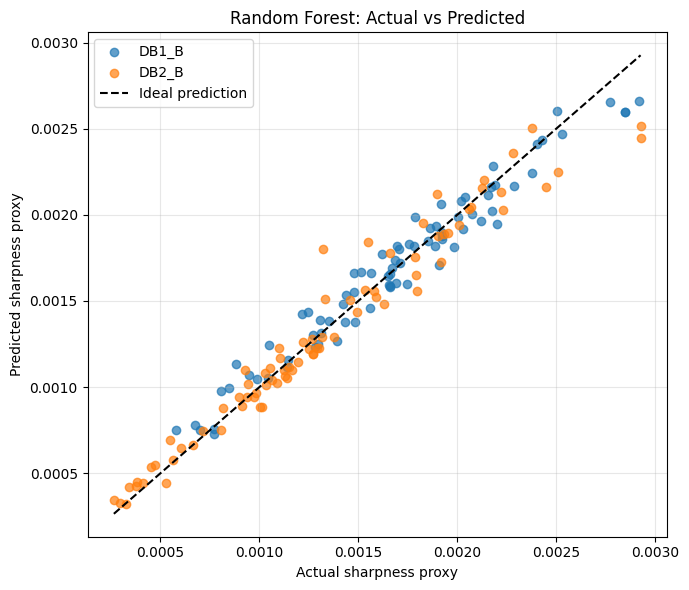

In [23]:

# DS-A5 | Step 8: Actual vs predicted

import matplotlib.pyplot as plt

rf = pred[pred["model"] == "Random Forest"].copy()

plt.figure(figsize=(7, 6))

for database in sorted(rf["database"].unique()):
    subset = rf[rf["database"] == database]

    plt.scatter(
        subset["actual_sharpness"],
        subset["predicted_sharpness"],
        alpha=0.7,
        label=database
    )

low = min(rf["actual_sharpness"].min(),
          rf["predicted_sharpness"].min())

high = max(rf["actual_sharpness"].max(),
           rf["predicted_sharpness"].max())

plt.plot([low, high], [low, high], "k--", label="Ideal prediction")

plt.xlabel("Actual sharpness proxy")
plt.ylabel("Predicted sharpness proxy")
plt.title("Random Forest: Actual vs Predicted")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


**Visualize prediction errors**

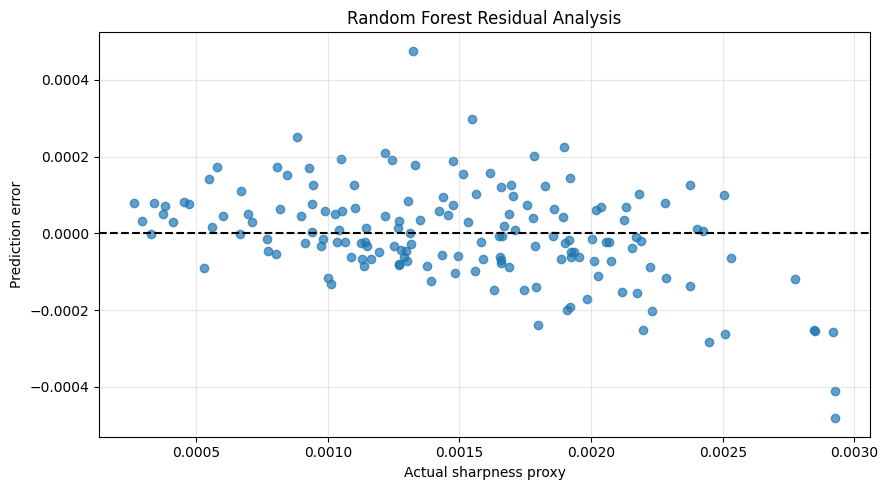

Residual statistics:


,Residual
count,160.000000
mean,-0.000004
std,0.000126
min,-0.000482
25%,-0.000067
50%,-0.000008
75%,0.000070
max,0.000476


In [24]:

# DS-A5 | Step 9: Residual analysis

plt.figure(figsize=(9, 5))

plt.scatter(
    rf["actual_sharpness"],
    rf["error"],
    alpha=0.7
)

plt.axhline(0, linestyle="--", color="black")

plt.xlabel("Actual sharpness proxy")
plt.ylabel("Prediction error")
plt.title("Random Forest Residual Analysis")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Residual statistics:")
display(rf["error"].describe().to_frame("Residual"))


#**Test cross-sensor generalization**

In [25]:

from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

cross_sensor_results = []

for train_db, test_db in [
    ("DB1_B", "DB2_B"),
    ("DB2_B", "DB1_B")
]:
    train_data = model_df[model_df["database"] == train_db]
    test_data = model_df[model_df["database"] == test_db]

    X_train = train_data[features]
    y_train = train_data[target]

    X_test = test_data[features]
    y_test = test_data[target]

    models = {
        "Baseline": DummyRegressor(strategy="mean"),
        "Random Forest": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", RandomForestRegressor(
                n_estimators=300,
                min_samples_leaf=2,
                random_state=42,
                n_jobs=-1
            ))
        ])
    }

    for model_name, model in models.items():
        model.fit(X_train, y_train)
        predictions = model.predict(X_test)

        cross_sensor_results.append({
            "train_database": train_db,
            "test_database": test_db,
            "model": model_name,
            "test_images": len(y_test),
            "MAE": mean_absolute_error(y_test, predictions),
            "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
            "R2": r2_score(y_test, predictions)
        })

cross_sensor_df = pd.DataFrame(cross_sensor_results)

display(cross_sensor_df)

cross_sensor_df.to_csv(
    "/content/DS_A5_results/cross_sensor_results.csv",
    index=False
)


,train_database,test_database,model,test_images,MAE,RMSE,R2
0,DB1_B,DB2_B,Baseline,80,0.000619,0.000726,-0.346560
1,DB1_B,DB2_B,Random Forest,80,0.000471,0.000580,0.141149
2,DB2_B,DB1_B,Baseline,80,0.000528,0.000648,-0.477878
3,DB2_B,DB1_B,Random Forest,80,0.000502,0.000611,-0.313007


**Investigate feature distribution differences**

In [26]:

# Compare feature distributions between databases

distribution_comparison = model_df.groupby("database")[features].agg(
    ["mean", "std"]
)

display(distribution_comparison)

# Calculate standardized mean differences
rows = []

for feature in features:
    db1 = model_df.loc[
        model_df["database"] == "DB1_B", feature
    ]
    db2 = model_df.loc[
        model_df["database"] == "DB2_B", feature
    ]

    pooled_std = np.sqrt(
        (db1.std()**2 + db2.std()**2) / 2
    )

    smd = (
        (db1.mean() - db2.mean()) / pooled_std
        if pooled_std > 0 else np.nan
    )

    rows.append({
        "feature": feature,
        "DB1_mean": db1.mean(),
        "DB2_mean": db2.mean(),
        "standardized_mean_difference": smd
    })

smd_df = pd.DataFrame(rows)
display(smd_df)

smd_df.to_csv(
    "/content/DS_A5_results/feature_distribution_comparison.csv",
    index=False
)


mean_intensity            contrast           gradient_mean            \
                   mean       std      mean       std          mean       std   
database                                                                        
DB1_B          0.901584  0.054118  0.216319  0.070897      0.223639  0.060398   
DB2_B          0.661565  0.104267  0.190305  0.054779      0.348635  0.100168   

         gradient_std           orientation_consistency            
                 mean       std                    mean       std  
database                                                           
DB1_B        0.523543  0.074177                0.737648  0.083524  
DB2_B        0.367280  0.078401                0.198858  0.082314

,feature,DB1_mean,DB2_mean,standardized_mean_difference
0,mean_intensity,0.901584,0.661565,2.889446
1,contrast,0.216319,0.190305,0.410611
2,gradient_mean,0.223639,0.348635,-1.511264
3,gradient_std,0.523543,0.367280,2.047524
4,orientation_consistency,0.737648,0.198858,6.497620


**Compare target distributions**

,count,mean,std,min,median,max
database,,,,,,
DB1_B,80,0.001685,0.000536,0.000580,0.001688,0.002917
DB2_B,80,0.001317,0.000630,0.000264,0.001236,0.002926


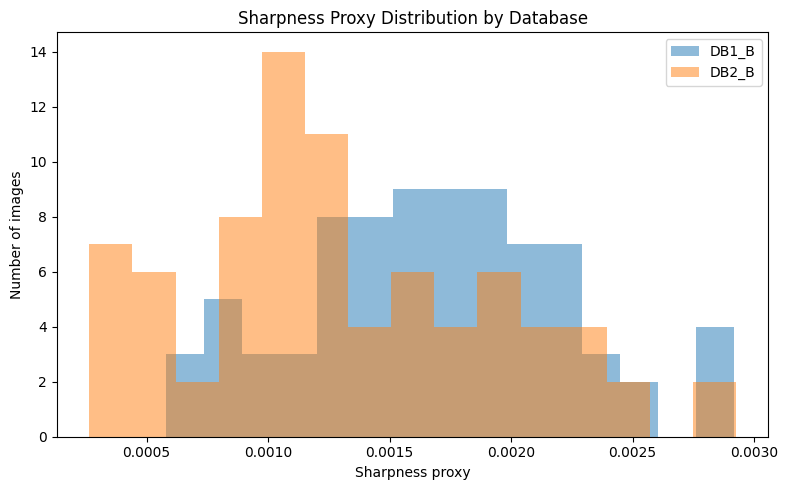

In [27]:

# Compare target distribution across databases

target_comparison = model_df.groupby("database")[target].agg(
    ["count", "mean", "std", "min", "median", "max"]
)

display(target_comparison)

# Plot target distributions
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

for database in sorted(model_df["database"].unique()):
    values = model_df.loc[
        model_df["database"] == database, target
    ]
    plt.hist(
        values,
        bins=15,
        alpha=0.5,
        label=database
    )

plt.xlabel("Sharpness proxy")
plt.ylabel("Number of images")
plt.title("Sharpness Proxy Distribution by Database")
plt.legend()
plt.tight_layout()
plt.show()


**Calculate the exact target difference**

In [28]:

# Exact target distribution comparison

target_stats = model_df.groupby("database")[target].agg(
    count="count",
    mean="mean",
    std="std",
    median="median",
    min="min",
    max="max"
)

display(target_stats)

# Standardized mean difference for target
db1 = model_df.loc[model_df["database"] == "DB1_B", target]
db2 = model_df.loc[model_df["database"] == "DB2_B", target]

pooled_std = np.sqrt(
    (db1.std()**2 + db2.std()**2) / 2
)

target_smd = (db1.mean() - db2.mean()) / pooled_std

print("Target standardized mean difference:", target_smd)
print("Difference in target means:", db1.mean() - db2.mean())


,count,mean,std,median,min,max
database,,,,,,
DB1_B,80,0.001685,0.000536,0.001688,0.000580,0.002917
DB2_B,80,0.001317,0.000630,0.001236,0.000264,0.002926


Target standardized mean difference: 0.6298718735896869
Difference in target means: 0.0003683845799969277


**Identify the most difficult predictions**

In [29]:

# Identify the 10 largest Random Forest prediction errors

rf_errors = predictions_df[
    predictions_df["model"] == "Random Forest"
].copy()

rf_errors["error"] = (
    rf_errors["predicted_sharpness"]
    - rf_errors["actual_sharpness"]
)

rf_errors["absolute_error"] = rf_errors["error"].abs()

worst_cases = rf_errors.sort_values(
    "absolute_error", ascending=False
).head(10)

display(
    worst_cases[
        [
            "database",
            "finger_id",
            "impression_id",
            "actual_sharpness",
            "predicted_sharpness",
            "error",
            "absolute_error"
        ]
    ]
)

worst_cases.to_csv(
    "/content/DS_A5_results/worst_prediction_errors.csv",
    index=False
)


,database,finger_id,impression_id,actual_sharpness,predicted_sharpness,error,absolute_error
50,DB2_B,105,3,0.002926,0.002444,-0.000482,0.000482
319,DB2_B,106,8,0.001323,0.001799,0.000476,0.000476
314,DB2_B,106,3,0.002926,0.002516,-0.000410,0.000410
62,DB2_B,110,7,0.001546,0.001843,0.000297,0.000297
247,DB2_B,102,8,0.002448,0.002164,-0.000284,0.000284
316,DB2_B,106,5,0.002509,0.002246,-0.000263,0.000263
38,DB1_B,105,7,0.002917,0.002661,-0.000256,0.000256
237,DB1_B,107,6,0.002850,0.002595,-0.000255,0.000255
226,DB1_B,102,3,0.002847,0.002595,-0.000252,0.000252
160,DB1_B,103,1,0.002199,0.001947,-0.000251,0.000251


In [30]:

# Examine input features for the 10 largest errors

feature_error_analysis = worst_cases.merge(
    model_df[
        [
            "database",
            "finger_id",
            "impression_id"
        ] + features
    ],
    on=["database", "finger_id", "impression_id"],
    how="left"
)

display(
    feature_error_analysis[
        [
            "database",
            "finger_id",
            "impression_id",
            "actual_sharpness",
            "predicted_sharpness",
            "absolute_error"
        ] + features
    ]
)


,database,finger_id,impression_id,actual_sharpness,predicted_sharpness,absolute_error,mean_intensity,contrast,gradient_mean,gradient_std,orientation_consistency
0,DB2_B,105,3,0.002926,0.002444,0.000482,0.487418,0.268921,0.567673,0.511151,0.200926
1,DB2_B,106,8,0.001323,0.001799,0.000476,0.680591,0.237994,0.341479,0.433550,0.221652
2,DB2_B,106,3,0.002926,0.002516,0.000410,0.452548,0.271346,0.562793,0.519327,0.378867
3,DB2_B,110,7,0.001546,0.001843,0.000297,0.500860,0.276495,0.426894,0.420082,0.311500
4,DB2_B,102,8,0.002448,0.002164,0.000284,0.433470,0.312867,0.489789,0.520446,0.196208
5,DB2_B,106,5,0.002509,0.002246,0.000263,0.615472,0.220243,0.499365,0.472712,0.404106
6,DB1_B,105,7,0.002917,0.002661,0.000256,0.844382,0.285804,0.348714,0.671928,0.605833
7,DB1_B,107,6,0.002850,0.002595,0.000255,0.902013,0.208463,0.341236,0.635475,0.572293
8,DB1_B,102,3,0.002847,0.002595,0.000252,0.876599,0.269230,0.311276,0.678913,0.628233
9,DB1_B,103,1,0.002199,0.001947,0.000251,0.936761,0.187781,0.231230,0.595373,0.816474


In [31]:

# Check missing feature values in the difficult observations

check_columns = [
    "database",
    "finger_id",
    "impression_id"
] + features

print("Missing feature values in model_df:")
display(model_df[check_columns].isna().sum())

print("\nCheck the specific incomplete observation:")
display(
    model_df[
        (model_df["database"] == "DB1_B") &
        (model_df["finger_id"] == 103) &
        (model_df["impression_id"] == 1)
    ][check_columns]
)

print("\nCheck duplicate image identifiers:")
print(
    model_df.duplicated(
        subset=["database", "finger_id", "impression_id"]
    ).sum()
)


Missing feature values in model_df:


,0
database,0
finger_id,0
impression_id,0
mean_intensity,0
contrast,0
gradient_mean,0
gradient_std,0
orientation_consistency,0



Check the specific incomplete observation:


,database,finger_id,impression_id,mean_intensity,contrast,gradient_mean,gradient_std,orientation_consistency
16,DB1_B,103,1,0.936761,0.187781,0.23123,0.595373,0.816474



Check duplicate image identifiers:
0


#**Summary**
This study investigates image-derived fingerprint sharpness-proxy estimation and cross-database generalization using 160 images from FVC2004 DB1_B and DB2_B. Because the available images did not provide verified chronological timestamps, an instructor-approved repeated-acquisition evaluation was used instead of temporal rolling-origin forecasting. Five image-derived features were extracted, and sharpness was used as an engineered regression target. A mean baseline and a Random Forest regressor were evaluated using five-fold GroupKFold validation, grouping images by database and finger identifier to prevent impressions from the same group appearing in both training and testing. The Random Forest achieved a mean MAE of 0.000094 and mean R² of 0.956353, outperforming the baseline. However, cross-database evaluation showed weaker generalization: R² was 0.141149 when training on DB1_B and testing on DB2_B, and -0.313007 in the reverse direction. Feature-distribution analysis revealed substantial differences, particularly in orientation consistency (absolute SMD = 6.498), while the sharpness-target SMD was 0.630. These findings are consistent with dataset shift and demonstrate that strong grouped-validation performance does not guarantee cross-database transfer. The study is limited by its small dataset and use of an image-derived target rather than independently annotated fingerprint-quality labels.